# Experiment 3 — Preprocessing 2: CLAHE + Morphological Opening on Brain Tumor MRI

This notebook evaluates the impact of spatial-domain preprocessing (**Percentile Clipping [5th, 95th] + CLAHE + Morphological Opening**) on the **Cheng Brain Tumor MRI** 3-class classification benchmark (Meningioma, Glioma, Pituitary) using **DINOv2 ViT-B/14** (`facebook/dinov2-base`) linear probing.

Following **Baharoon et al. (2024, arXiv:2312.02366v4)**, the pretrained vision transformer encoder remains completely frozen, and only a lightweight linear classification head is trained on top of the 768-dimensional `[CLS]` token representations.

### Experimental Comparison

| Configuration Dimension | Brain Tumor Baseline (E1) | This Experiment (E3) |
|---|---|---|
| **Preprocessing Pipeline** | Percentile Clip [5th, 95th] | Percentile Clip [5th, 95th] → CLAHE → Morphological Opening (Blended) |
| **Backbone Architecture** | DINOv2 ViT-B/14 (Frozen) | DINOv2 ViT-B/14 (Frozen) |
| **Classification Head** | Linear Head (768 → 3) | Linear Head (768 → 3) |
| **Batch Size** | 128 | 128 |
| **Optimizer & Learning Rate** | SGD (lr=0.01, momentum=0.9) | SGD (lr=0.01, momentum=0.9) |
| **Training Epochs** | 20 | 20 |
| **Dropout** | 0.1 | 0.1 |
| **Target Classes** | 3 (Meningioma=0, Glioma=1, Pituitary=2) | 3 (Meningioma=0, Glioma=1, Pituitary=2) |

In [1]:
import os
from pathlib import Path
import subprocess
import sys

repo_dir: Path | None = None
for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate / "cheng-brain-tumor-mri-detection.ndjson").is_file() or (candidate / "src").is_dir():
        repo_dir = candidate
        break

if repo_dir is None:
    repo_url = "https://github.com/RudhanLodhi/DinoV2_PEFT.git"
    repo_dir = Path.cwd() / "DinoV2B"
    subprocess.run(["git", "clone", repo_url, str(repo_dir)], check=True)

os.chdir(repo_dir)
subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "torch", "torchvision", "transformers", "scikit-learn",
        "matplotlib", "seaborn", "pandas", "opencv-python-headless",
        "requests", "tqdm", "-q",
    ],
    check=False,
)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    CHECKPOINT_DIR: Path = Path("/content/drive/MyDrive/dinov2_peft/exp3_pre_clahe_brain_tumor")
except ImportError:
    CHECKPOINT_DIR = Path("checkpoints/exp3_pre_clahe_brain_tumor")

OUTPUT_DIR: Path = Path("outputs/exp3_pre_clahe_brain_tumor")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Working directory: {repo_dir}")
print(f"Checkpoint directory established at: {CHECKPOINT_DIR}")

Mounted at /content/drive
Working directory: /content/DinoV2B
Checkpoint directory established at: /content/drive/MyDrive/dinov2_peft/exp3_pre_clahe_brain_tumor


## 1. Hyperparameter Configuration

Hyperparameter specifications adhering to the exact protocol of `0_Baseline_BrainTumor` and Baharoon et al. (2024):
- **Image Resolution:** 224 x 224 pixels
- **Batch Size:** 128
- **Optimizer:** SGD with momentum = 0.9, weight_decay = 1e-4
- **Learning Rate:** 0.01
- **Epochs:** 20
- **Dropout:** 0.1
- **Preprocessing:** Foreground MRI percentile clipping [5th, 95th] + CLAHE (clipLimit=1.5, tileGridSize=(8,8)) + Morphological Opening (3x3 ellipse) with residual blend ($\alpha=0.5$)
- **Data Augmentation:** RandomResizedCrop(224, scale=(0.75, 1.0), BICUBIC) + RandomHorizontalFlip(p=0.5)

In [2]:
import random
from typing import Any
import numpy as np
import torch

HPARAMS: dict[str, Any] = {
    "model_id": "facebook/dinov2-base",
    "architecture": "ViT-B/14",
    "image_size": 224,
    "batch_size": 128,
    "optimizer": "SGD",
    "sgd_momentum": 0.9,
    "weight_decay": 1e-4,
    "learning_rate": 1e-2,
    "epochs": 20,
    "dropout": 0.1,
    "num_workers": 2,
    "seed": 42,
    "mri_clip_percentile_low": 5.0,
    "mri_clip_percentile_high": 95.0,
    "clahe_clip": 1.5,
    "clahe_grid": (8, 8),
    "morph_kernel_size": 3,
    "blend_alpha": 0.5,
    "crop_scale_min": 0.75,
    "crop_scale_max": 1.0,
    "flip_prob": 0.5,
    "normalize_mean": [0.485, 0.456, 0.406],
    "normalize_std": [0.229, 0.224, 0.225],
    "preprocessing": "MRIClip + CLAHE + MorphOpen",
}

CLASS_NAMES: dict[int, str] = {
    0: "Meningioma",
    1: "Glioma",
    2: "Pituitary",
}
CLASS_LIST: list[str] = [CLASS_NAMES[i] for i in range(3)]
NUM_CLASSES: int = 3

BASE_PAPER_RESULTS: dict[str, dict[str, Any]] = {
    "Supervised DenseNet201": {"auroc": 0.960, "method": "Full Fine-Tuning", "architecture": "DenseNet201"},
    "Supervised ViT-L/16": {"auroc": 0.975, "method": "Full Fine-Tuning", "architecture": "ViT-L/16"},
    "DINOv2 ViT-S/14": {"auroc": 0.962, "method": "Linear Probe", "architecture": "ViT-S/14"},
    "DINOv2 ViT-B/14 (Target)": {"auroc": 0.972, "method": "Linear Probe", "architecture": "ViT-B/14"},
    "DINOv2 ViT-L/14": {"auroc": 0.974, "method": "Linear Probe", "architecture": "ViT-L/14"},
    "DINOv2 ViT-g/14": {"auroc": 0.976, "method": "Linear Probe", "architecture": "ViT-g/14"},
}

def seed_everything(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(HPARAMS["seed"])

print(f"Target Model: {HPARAMS['model_id']}")
print(f"Number of Classes: {NUM_CLASSES} ({', '.join(CLASS_LIST)})")
print(
    f"Batch Size: {HPARAMS['batch_size']} | Optimizer: {HPARAMS['optimizer']} "
    f"(lr={HPARAMS['learning_rate']}, momentum={HPARAMS['sgd_momentum']}) | "
    f"Epochs: {HPARAMS['epochs']}"
)

Target Model: facebook/dinov2-base
Number of Classes: 3 (Meningioma, Glioma, Pituitary)
Batch Size: 128 | Optimizer: SGD (lr=0.01, momentum=0.9) | Epochs: 20


## 2. Dataset Loading & Image Download

Parses `cheng-brain-tumor-mri-detection.ndjson` directly (without relying on `src/`) and downloads all 3,064 MRI slices to `data/brain_tumor/images`.

Train split images: 2,133
Val split images:   651
Test split images:  280
Total dataset size: 3,064 images


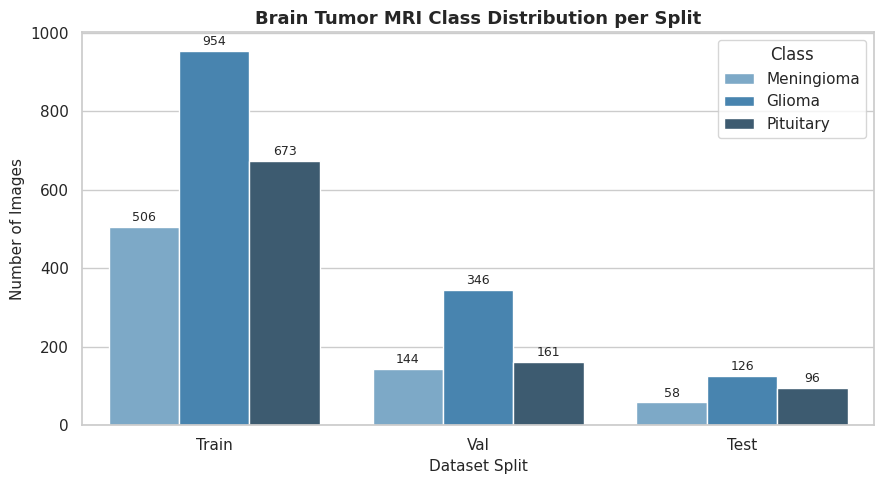

In [3]:
from collections import Counter
import json
from pathlib import Path
from typing import Any
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

NDJSON_PATH: Path = Path("cheng-brain-tumor-mri-detection.ndjson")

def load_ndjson_records(
    ndjson_path: str | Path,
) -> tuple[list[dict[str, Any]], list[dict[str, Any]], list[dict[str, Any]]]:
    """Parses the Ultralytics NDJSON manifest into train, val, and test record lists."""
    train_records: list[dict[str, Any]] = []
    val_records: list[dict[str, Any]] = []
    test_records: list[dict[str, Any]] = []

    with open(ndjson_path, "r", encoding="utf-8") as f:
        for line in f:
            line_str = line.strip()
            if not line_str:
                continue
            row: dict[str, Any] = json.loads(line_str)
            if row.get("type") != "image":
                continue

            boxes = row.get("annotations", {}).get("boxes", [])
            if not boxes:
                continue
            label = int(boxes[0][0])

            record = {
                "file": row["file"],
                "url": row.get("url", ""),
                "split": row.get("split", "train"),
                "label": label,
            }
            split = record["split"]
            if split == "train":
                train_records.append(record)
            elif split in ("val", "valid"):
                val_records.append(record)
            elif split == "test":
                test_records.append(record)

    return train_records, val_records, test_records

train_recs, val_recs, test_recs = load_ndjson_records(NDJSON_PATH)

print(f"Train split images: {len(train_recs):,}")
print(f"Val split images:   {len(val_recs):,}")
print(f"Test split images:  {len(test_recs):,}")
print(f"Total dataset size: {len(train_recs) + len(val_recs) + len(test_recs):,} images")

split_records_map: dict[str, list[dict[str, Any]]] = {
    "Train": train_recs,
    "Val": val_recs,
    "Test": test_recs,
}

chart_data: list[dict[str, Any]] = []
for split_name, recs in split_records_map.items():
    counts: Counter[int] = Counter(int(r["label"]) for r in recs)
    for class_id in range(NUM_CLASSES):
        chart_data.append(
            {
                "Split": split_name,
                "Class": CLASS_NAMES[class_id],
                "Count": counts.get(class_id, 0),
            }
        )

df_dist: pd.DataFrame = pd.DataFrame(chart_data)

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=df_dist, x="Split", y="Count", hue="Class", palette="Blues_d", ax=ax)
ax.set_title("Brain Tumor MRI Class Distribution per Split", fontsize=13, fontweight="bold")
ax.set_xlabel("Dataset Split", fontsize=11)
ax.set_ylabel("Number of Images", fontsize=11)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f"{int(height)}",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=9,
            xytext=(0, 2),
            textcoords="offset points",
        )

plt.tight_layout()
plt.show()

In [4]:
from io import BytesIO
from PIL import Image
import requests
from tqdm.auto import tqdm

IMAGE_ROOT: Path = Path("data/brain_tumor/images")
IMAGE_ROOT.mkdir(parents=True, exist_ok=True)

def download_images_from_ndjson(
    records: list[dict[str, Any]],
    image_root: str | Path,
    max_failures: int = 50,
) -> Path:
    """Downloads all MRI slices referenced in the parsed NDJSON records to local disk."""
    failures: int = 0
    target_root: Path = Path(image_root)
    for r in tqdm(records, desc="Downloading MRI images"):
        dest: Path = target_root / r["file"]
        if dest.exists() and dest.stat().st_size > 0:
            failures = 0
            continue
        try:
            resp = requests.get(r["url"], timeout=15)
            resp.raise_for_status()
            img: Image.Image = Image.open(BytesIO(resp.content)).convert("RGB")
            img.save(dest)
            failures = 0
        except Exception as e:
            failures += 1
            if failures >= max_failures:
                raise RuntimeError(
                    f"Too many consecutive download failures ({max_failures}). Last error: {e}"
                )
    return target_root

all_records = train_recs + val_recs + test_recs
download_images_from_ndjson(all_records, IMAGE_ROOT)

num_files = len(list(IMAGE_ROOT.glob("*.jpg")))
print(f"Images ready in: {IMAGE_ROOT}")
print(f"Total images verified on disk: {num_files:,}")
assert num_files >= len(all_records), f"Expected {len(all_records)} images on disk, found {num_files}!"

Images ready in: data/brain_tumor/images
Total images verified on disk: 3,064


In [5]:
import cv2
import numpy as np
from PIL import Image

class MRIEnhancedPreprocessing:
    """Applies foreground percentile clipping, CLAHE, and morphological opening with residual blending.

    Steps:
    1. Convert input PIL Image to single-channel grayscale float32.
    2. Compute [low_pct, high_pct] intensity percentiles on foreground brain pixels (arr > 5)
       so black background pixels do not skew the clipping range, then rescale to [0, 255].
    3. Apply CLAHE (adaptive local contrast enhancement) and Morphological Opening (3x3 elliptical
       structuring element to remove isolated bright speckle noise) while keeping background masked.
    4. Alpha-blend the CLAHE+Morph image with the percentile-clipped image to preserve global
       intensity contrast for DINOv2 patch embeddings while enhancing local lesion boundaries.
    """

    def __init__(
        self,
        low_pct: float = 5.0,
        high_pct: float = 95.0,
        clahe_clip: float = 1.5,
        clahe_grid: tuple[int, int] = (8, 8),
        morph_kernel_size: int = 3,
        blend_alpha: float = 0.5,
    ) -> None:
        self.low_pct: float = low_pct
        self.high_pct: float = high_pct
        self.clahe_clip: float = clahe_clip
        self.clahe_grid: tuple[int, int] = clahe_grid
        self.morph_kernel_size: int = morph_kernel_size
        self.blend_alpha: float = blend_alpha
        self.kernel: np.ndarray = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE,
            (morph_kernel_size, morph_kernel_size),
        )

    def process_stages(
        self, img: Image.Image
    ) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
        """Returns (raw_gray, clipped_u8, clahe_u8, final_blended_u8) for inspection and training."""
        raw_gray: np.ndarray = np.array(img.convert("L"), dtype=np.float32)
        fg_mask: np.ndarray = raw_gray > 5.0

        if np.any(fg_mask):
            lo: float = float(np.percentile(raw_gray[fg_mask], self.low_pct))
            hi: float = float(np.percentile(raw_gray[fg_mask], self.high_pct))
        else:
            lo = float(np.percentile(raw_gray, self.low_pct))
            hi = float(np.percentile(raw_gray, self.high_pct))

        if hi > lo:
            clipped = np.clip(raw_gray, lo, hi)
            clipped = (clipped - lo) / (hi - lo) * 255.0
            clipped[~fg_mask] = 0.0
        else:
            clipped = raw_gray.copy()

        clipped_u8: np.ndarray = np.clip(clipped, 0, 255).astype(np.uint8)

        # Instantiate CLAHE locally per call for multi-worker DataLoader safety
        clahe = cv2.createCLAHE(clipLimit=self.clahe_clip, tileGridSize=self.clahe_grid)
        clahe_u8: np.ndarray = clahe.apply(clipped_u8)
        clahe_u8[~fg_mask] = 0

        morph_u8: np.ndarray = cv2.morphologyEx(clahe_u8, cv2.MORPH_OPEN, self.kernel)
        morph_u8[~fg_mask] = 0

        blended: np.ndarray = (
            (1.0 - self.blend_alpha) * clipped_u8.astype(np.float32)
            + self.blend_alpha * morph_u8.astype(np.float32)
        )
        final_u8: np.ndarray = np.clip(blended, 0, 255).astype(np.uint8)
        return raw_gray.astype(np.uint8), clipped_u8, clahe_u8, final_u8

    def __call__(self, img: Image.Image) -> Image.Image:
        _, _, _, final_u8 = self.process_stages(img)
        return Image.fromarray(final_u8).convert("RGB")

mri_preprocessor = MRIEnhancedPreprocessing(
    low_pct=HPARAMS["mri_clip_percentile_low"],
    high_pct=HPARAMS["mri_clip_percentile_high"],
    clahe_clip=HPARAMS["clahe_clip"],
    clahe_grid=HPARAMS["clahe_grid"],
    morph_kernel_size=HPARAMS["morph_kernel_size"],
    blend_alpha=HPARAMS["blend_alpha"],
)
print("MRIEnhancedPreprocessing initialized successfully.")

MRIEnhancedPreprocessing initialized successfully.


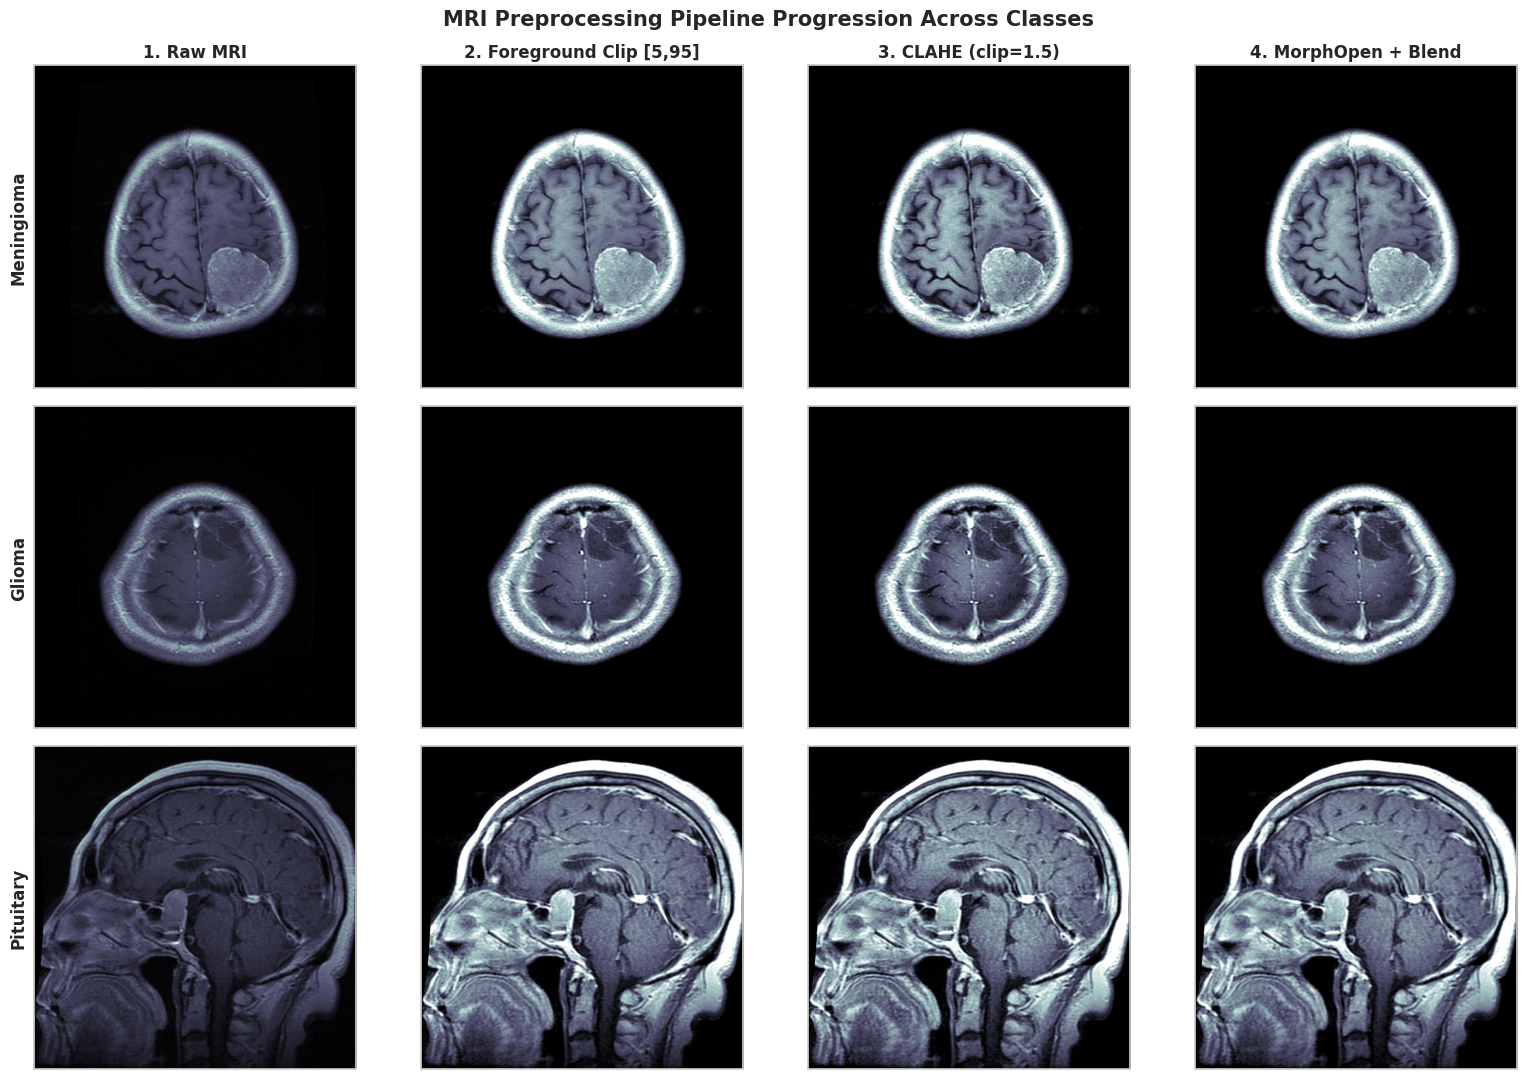

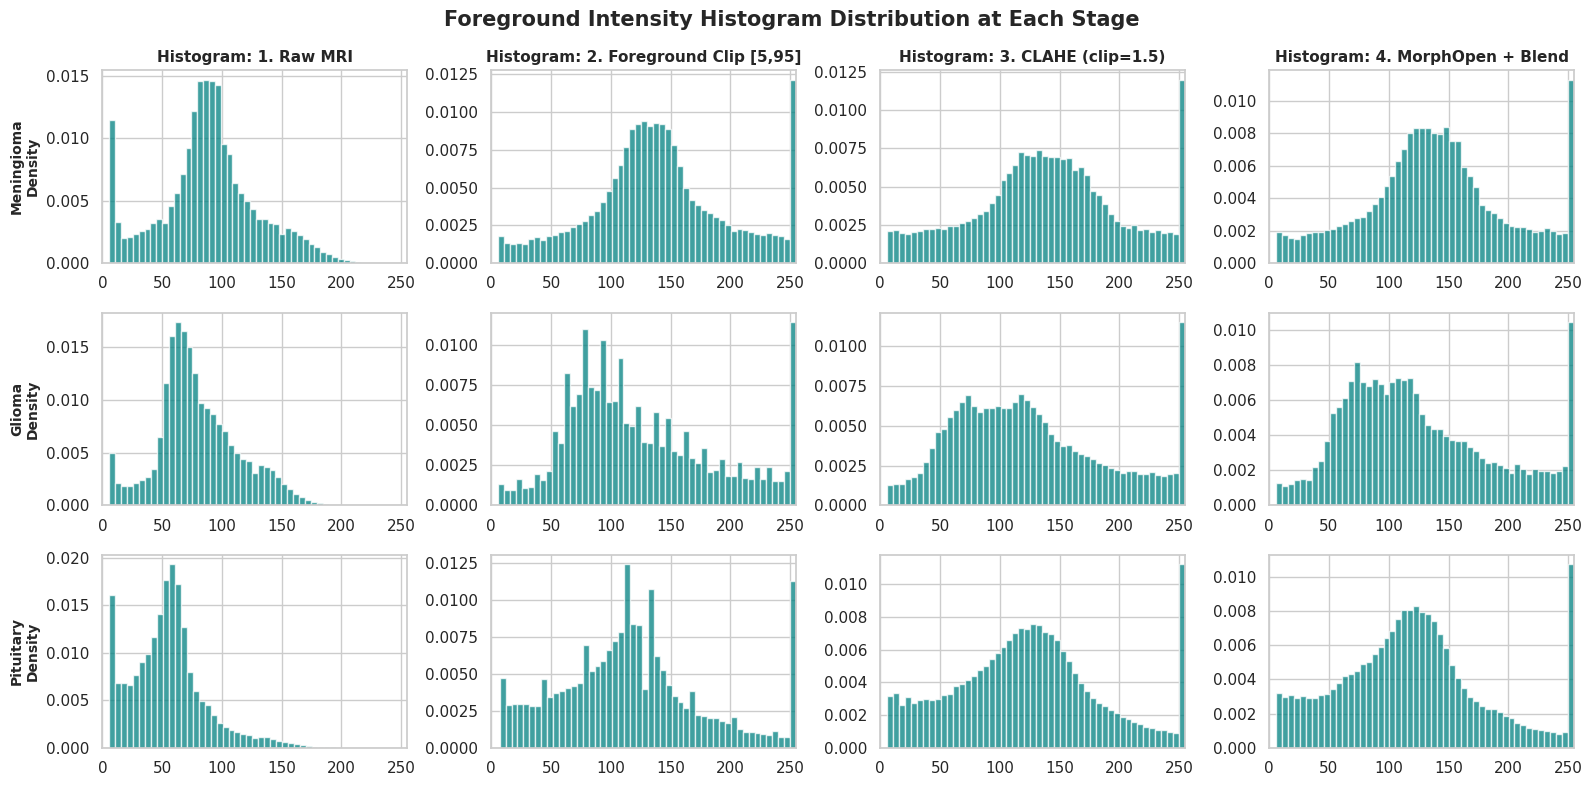

In [6]:
def get_class_sample(records: list[dict[str, Any]], target_class: int) -> Image.Image:
    for rec in records:
        if int(rec["label"]) == target_class:
            local_path = IMAGE_ROOT / rec["file"]
            if local_path.is_file():
                return Image.open(local_path).convert("RGB")
    raise FileNotFoundError(f"No image found on disk for class {target_class}")

samples = {cls_idx: get_class_sample(train_recs, cls_idx) for cls_idx in range(NUM_CLASSES)}

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
stage_names = [
    "1. Raw MRI",
    "2. Foreground Clip [5,95]",
    "3. CLAHE (clip=1.5)",
    "4. MorphOpen + Blend",
]
stage_images: dict[int, list[np.ndarray]] = {}

for row_idx, cls_idx in enumerate(range(NUM_CLASSES)):
    raw_u8, clipped_u8, clahe_u8, final_u8 = mri_preprocessor.process_stages(samples[cls_idx])
    stage_images[cls_idx] = [raw_u8, clipped_u8, clahe_u8, final_u8]

    for col_idx in range(4):
        ax = axes[row_idx, col_idx]
        ax.imshow(stage_images[cls_idx][col_idx], cmap="bone")
        if row_idx == 0:
            ax.set_title(stage_names[col_idx], fontsize=12, fontweight="bold")
        if col_idx == 0:
            ax.set_ylabel(CLASS_NAMES[cls_idx], fontsize=12, fontweight="bold")
        ax.set_xticks([])
        ax.set_yticks([])

plt.suptitle("MRI Preprocessing Pipeline Progression Across Classes", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

fig_hist, axes_hist = plt.subplots(3, 4, figsize=(16, 8))
for row_idx, cls_idx in enumerate(range(NUM_CLASSES)):
    for col_idx in range(4):
        ax_h = axes_hist[row_idx, col_idx]
        pixel_data = stage_images[cls_idx][col_idx].flatten()
        ax_h.hist(pixel_data[pixel_data > 5], bins=50, color="teal", alpha=0.75, density=True)
        if row_idx == 0:
            ax_h.set_title(f"Histogram: {stage_names[col_idx]}", fontsize=11, fontweight="bold")
        if col_idx == 0:
            ax_h.set_ylabel(f"{CLASS_NAMES[cls_idx]}\nDensity", fontsize=10, fontweight="bold")
        ax_h.set_xlim(0, 255)

plt.suptitle("Foreground Intensity Histogram Distribution at Each Stage", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

In [7]:
from typing import Callable
import torch
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

def build_brain_tumor_transforms(
    image_size: int = 224,
    mean: list[float] | None = None,
    std: list[float] | None = None,
) -> tuple[transforms.Compose, transforms.Compose]:
    """Constructs training and validation transforms matching 0_Baseline_BrainTumor with BICUBIC interpolation."""
    norm_mean: list[float] = mean if mean is not None else [0.485, 0.456, 0.406]
    norm_std: list[float] = std if std is not None else [0.229, 0.224, 0.225]

    preproc = MRIEnhancedPreprocessing(
        low_pct=HPARAMS["mri_clip_percentile_low"],
        high_pct=HPARAMS["mri_clip_percentile_high"],
        clahe_clip=HPARAMS["clahe_clip"],
        clahe_grid=HPARAMS["clahe_grid"],
        morph_kernel_size=HPARAMS["morph_kernel_size"],
        blend_alpha=HPARAMS["blend_alpha"],
    )

    train_tf = transforms.Compose(
        [
            preproc,
            transforms.RandomResizedCrop(
                image_size,
                scale=(HPARAMS["crop_scale_min"], HPARAMS["crop_scale_max"]),
                interpolation=transforms.InterpolationMode.BICUBIC,
            ),
            transforms.RandomHorizontalFlip(p=HPARAMS["flip_prob"]),
            transforms.ToTensor(),
            transforms.Normalize(mean=norm_mean, std=norm_std),
        ]
    )

    val_tf = transforms.Compose(
        [
            preproc,
            transforms.Resize(256, interpolation=transforms.InterpolationMode.BICUBIC),
            transforms.CenterCrop(image_size),
            transforms.ToTensor(),
            transforms.Normalize(mean=norm_mean, std=norm_std),
        ]
    )

    return train_tf, val_tf

class BrainTumorMRIDataset(Dataset):
    """Self-contained PyTorch Dataset for Cheng Brain Tumor MRI slices."""

    def __init__(
        self,
        records: list[dict[str, Any]],
        image_root: str | Path,
        transform: Callable | None = None,
    ) -> None:
        self.records: list[dict[str, Any]] = records
        self.image_root: Path = Path(image_root)
        self.transform: Callable | None = transform

    def __len__(self) -> int:
        return len(self.records)

    def __getitem__(self, idx: int) -> dict[str, Any]:
        rec = self.records[idx]
        img_path = self.image_root / rec["file"]
        if not img_path.is_file():
            raise FileNotFoundError(
                f"MRI slice not found at {img_path}. Run the download cell first."
            )
        img = Image.open(img_path).convert("RGB")
        pixel_values = self.transform(img) if self.transform is not None else transforms.ToTensor()(img)
        label = int(rec["label"])
        return {
            "pixel_values": pixel_values,
            "label": torch.tensor(label, dtype=torch.long),
            "file": rec["file"],
        }

train_transforms, val_transforms = build_brain_tumor_transforms(
    image_size=HPARAMS["image_size"],
    mean=HPARAMS["normalize_mean"],
    std=HPARAMS["normalize_std"],
)

train_dataset = BrainTumorMRIDataset(train_recs, IMAGE_ROOT, transform=train_transforms)
val_dataset = BrainTumorMRIDataset(val_recs, IMAGE_ROOT, transform=val_transforms)
test_dataset = BrainTumorMRIDataset(test_recs, IMAGE_ROOT, transform=val_transforms)

train_loader = DataLoader(
    train_dataset,
    batch_size=HPARAMS["batch_size"],
    shuffle=True,
    num_workers=HPARAMS["num_workers"],
    pin_memory=True,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=HPARAMS["batch_size"],
    shuffle=False,
    num_workers=HPARAMS["num_workers"],
    pin_memory=True,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=HPARAMS["batch_size"],
    shuffle=False,
    num_workers=HPARAMS["num_workers"],
    pin_memory=True,
)

print(f"Train Dataset: {len(train_dataset):,} samples ({len(train_loader)} batches)")
print(f"Val Dataset:   {len(val_dataset):,} samples ({len(val_loader)} batches)")
print(f"Test Dataset:  {len(test_dataset):,} samples ({len(test_loader)} batches)")

Train Dataset: 2,133 samples (17 batches)
Val Dataset:   651 samples (6 batches)
Test Dataset:  280 samples (3 batches)


## 3. Model Architecture (Frozen DINOv2 ViT-B/14 + Normalized Linear Probe)

Loads `facebook/dinov2-base` directly via `transformers.AutoModel` (no `src/` wrapper needed), freezes all encoder weights, and attaches a normalized linear classification head (`LayerNorm(768) -> Dropout(0.1) -> Linear(768, 3)`).

In [8]:
import torch
import torch.nn as nn
from transformers import AutoModel

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class DINOv2LinearProbe(nn.Module):
    """Frozen DINOv2 ViT-B/14 encoder with a trainable linear classification head."""

    def __init__(
        self,
        model_id: str = "facebook/dinov2-base",
        num_classes: int = 3,
        dropout: float = 0.1,
    ) -> None:
        super().__init__()
        self.backbone = AutoModel.from_pretrained(model_id)
        for param in self.backbone.parameters():
            param.requires_grad = False
        self.backbone.eval()

        hidden_dim: int = int(self.backbone.config.hidden_size)
        self.head = nn.Sequential(
            nn.LayerNorm(hidden_dim),
            nn.Dropout(p=dropout),
            nn.Linear(hidden_dim, num_classes),
        )
        nn.init.normal_(self.head[-1].weight, mean=0.0, std=0.01)
        nn.init.zeros_(self.head[-1].bias)

    def train(self, mode: bool = True) -> "DINOv2LinearProbe":
        super().train(mode)
        # Keep frozen backbone in eval mode at all times
        self.backbone.eval()
        return self

    def forward(self, pixel_values: torch.Tensor) -> torch.Tensor:
        with torch.no_grad():
            outputs = self.backbone(pixel_values=pixel_values)
            cls_token = outputs.last_hidden_state[:, 0, :]
        return self.head(cls_token)

model = DINOv2LinearProbe(
    model_id=HPARAMS["model_id"],
    num_classes=NUM_CLASSES,
    dropout=HPARAMS["dropout"],
).to(device)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
param_pct = 100.0 * trainable_params / total_params

print(f"Backbone: {HPARAMS['model_id']} on {device}")
print(f"Trainable parameters: {trainable_params:,} / {total_params:,} ({param_pct:.4f}%)")

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Backbone: facebook/dinov2-base on cuda
Trainable parameters: 3,843 / 86,584,323 (0.0044%)


## 4. Training & Evaluation Loop

In [9]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from torch.optim import SGD
from torch.optim.lr_scheduler import CosineAnnealingLR

criterion = nn.CrossEntropyLoss()

optimizer = SGD(
    model.head.parameters(),
    lr=HPARAMS["learning_rate"],
    momentum=HPARAMS["sgd_momentum"],
    weight_decay=HPARAMS["weight_decay"],
)

scheduler = CosineAnnealingLR(optimizer, T_max=HPARAMS["epochs"], eta_min=1e-4)

def compute_multiclass_metrics(
    labels: np.ndarray,
    probs: np.ndarray,
) -> dict[str, Any]:
    """Computes accuracy, macro-F1, macro OvR AUROC, and per-class AUROCs."""
    preds = np.argmax(probs, axis=1)
    acc = float(accuracy_score(labels, preds))
    macro_f1 = float(f1_score(labels, preds, average="macro", zero_division=0.0))

    per_class_auroc: dict[str, float] = {}
    valid_aurocs: list[float] = []

    for c_idx, c_name in CLASS_NAMES.items():
        binary_targets = (labels == c_idx).astype(int)
        if len(np.unique(binary_targets)) > 1:
            score = float(roc_auc_score(binary_targets, probs[:, c_idx]))
            per_class_auroc[c_name.lower()] = score
            valid_aurocs.append(score)
        else:
            per_class_auroc[c_name.lower()] = float("nan")

    macro_auroc = float(np.mean(valid_aurocs)) if valid_aurocs else float("nan")
    return {
        "accuracy": acc,
        "macro_f1": macro_f1,
        "macro_auroc": macro_auroc,
        "per_class_auroc": per_class_auroc,
    }

print("Training criterion, SGD optimizer, CosineAnnealingLR scheduler, and metrics helper ready.")

Training criterion, SGD optimizer, CosineAnnealingLR scheduler, and metrics helper ready.


In [10]:
import copy
import time
import torch.nn.functional as F

num_epochs: int = HPARAMS["epochs"]
history: dict[str, list[float]] = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_auroc": [],
    "val_macro_f1": [],
}

best_val_auroc: float = 0.0
best_val_acc: float = 0.0
best_val_metrics: dict[str, Any] = {}
best_head_state: dict[str, Any] = {}
start_time: float = time.time()

print(f"Beginning training for {num_epochs} epochs on device: {device}")

for epoch in range(1, num_epochs + 1):
    model.train()
    running_train_loss: float = 0.0

    for batch in train_loader:
        images = batch["pixel_values"].to(device, non_blocking=True)
        targets = batch["label"].to(device, non_blocking=True)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

    scheduler.step()
    epoch_train_loss = running_train_loss / len(train_dataset)

    model.eval()
    running_val_loss: float = 0.0
    val_probs_list: list[np.ndarray] = []
    val_labels_list: list[np.ndarray] = []

    with torch.no_grad():
        for batch in val_loader:
            images = batch["pixel_values"].to(device, non_blocking=True)
            targets = batch["label"].to(device, non_blocking=True)
            logits = model(images)
            loss = criterion(logits, targets)
            running_val_loss += loss.item() * images.size(0)

            probs = F.softmax(logits, dim=-1).cpu().numpy()
            val_probs_list.append(probs)
            val_labels_list.append(targets.cpu().numpy())

    epoch_val_loss = running_val_loss / len(val_dataset)
    all_val_probs = np.concatenate(val_probs_list, axis=0)
    all_val_labels = np.concatenate(val_labels_list, axis=0)
    val_metrics = compute_multiclass_metrics(all_val_labels, all_val_probs)

    history["train_loss"].append(epoch_train_loss)
    history["val_loss"].append(epoch_val_loss)
    history["val_accuracy"].append(val_metrics["accuracy"])
    history["val_macro_auroc"].append(val_metrics["macro_auroc"])
    history["val_macro_f1"].append(val_metrics["macro_f1"])

    if val_metrics["macro_auroc"] >= best_val_auroc:
        best_val_auroc = val_metrics["macro_auroc"]
        best_val_acc = val_metrics["accuracy"]
        best_val_metrics = val_metrics
        best_head_state = copy.deepcopy(model.head.state_dict())
        torch.save(best_head_state, CHECKPOINT_DIR / "best_brain_tumor_clahe.pt")

    print(
        f"Epoch [{epoch:02d}/{num_epochs:02d}] "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Val Acc: {val_metrics['accuracy']:.4f} | "
        f"Val AUROC: {val_metrics['macro_auroc']:.4f} | "
        f"Val Macro-F1: {val_metrics['macro_f1']:.4f}"
    )

training_time_s: float = time.time() - start_time
print(
    f"\nTraining completed in {training_time_s:.1f}s. "
    f"Best Val AUROC: {best_val_auroc:.4f} | Best Val Acc: {best_val_acc:.4f}"
)

if best_head_state:
    model.head.load_state_dict(best_head_state)

Beginning training for 20 epochs on device: cuda
Epoch [01/20] Train Loss: 0.6737 | Val Loss: 0.4579 | Val Acc: 0.8111 | Val AUROC: 0.9374 | Val Macro-F1: 0.7659
Epoch [02/20] Train Loss: 0.3994 | Val Loss: 0.4138 | Val Acc: 0.8418 | Val AUROC: 0.9537 | Val Macro-F1: 0.7794
Epoch [03/20] Train Loss: 0.3470 | Val Loss: 0.4325 | Val Acc: 0.8402 | Val AUROC: 0.9527 | Val Macro-F1: 0.7904
Epoch [04/20] Train Loss: 0.3306 | Val Loss: 0.3208 | Val Acc: 0.8756 | Val AUROC: 0.9646 | Val Macro-F1: 0.8476
Epoch [05/20] Train Loss: 0.2695 | Val Loss: 0.3181 | Val Acc: 0.8664 | Val AUROC: 0.9666 | Val Macro-F1: 0.8246
Epoch [06/20] Train Loss: 0.2545 | Val Loss: 0.3509 | Val Acc: 0.8664 | Val AUROC: 0.9612 | Val Macro-F1: 0.8359
Epoch [07/20] Train Loss: 0.2622 | Val Loss: 0.3434 | Val Acc: 0.8679 | Val AUROC: 0.9626 | Val Macro-F1: 0.8401
Epoch [08/20] Train Loss: 0.2479 | Val Loss: 0.3064 | Val Acc: 0.8756 | Val AUROC: 0.9682 | Val Macro-F1: 0.8387
Epoch [09/20] Train Loss: 0.2276 | Val Loss: 0.

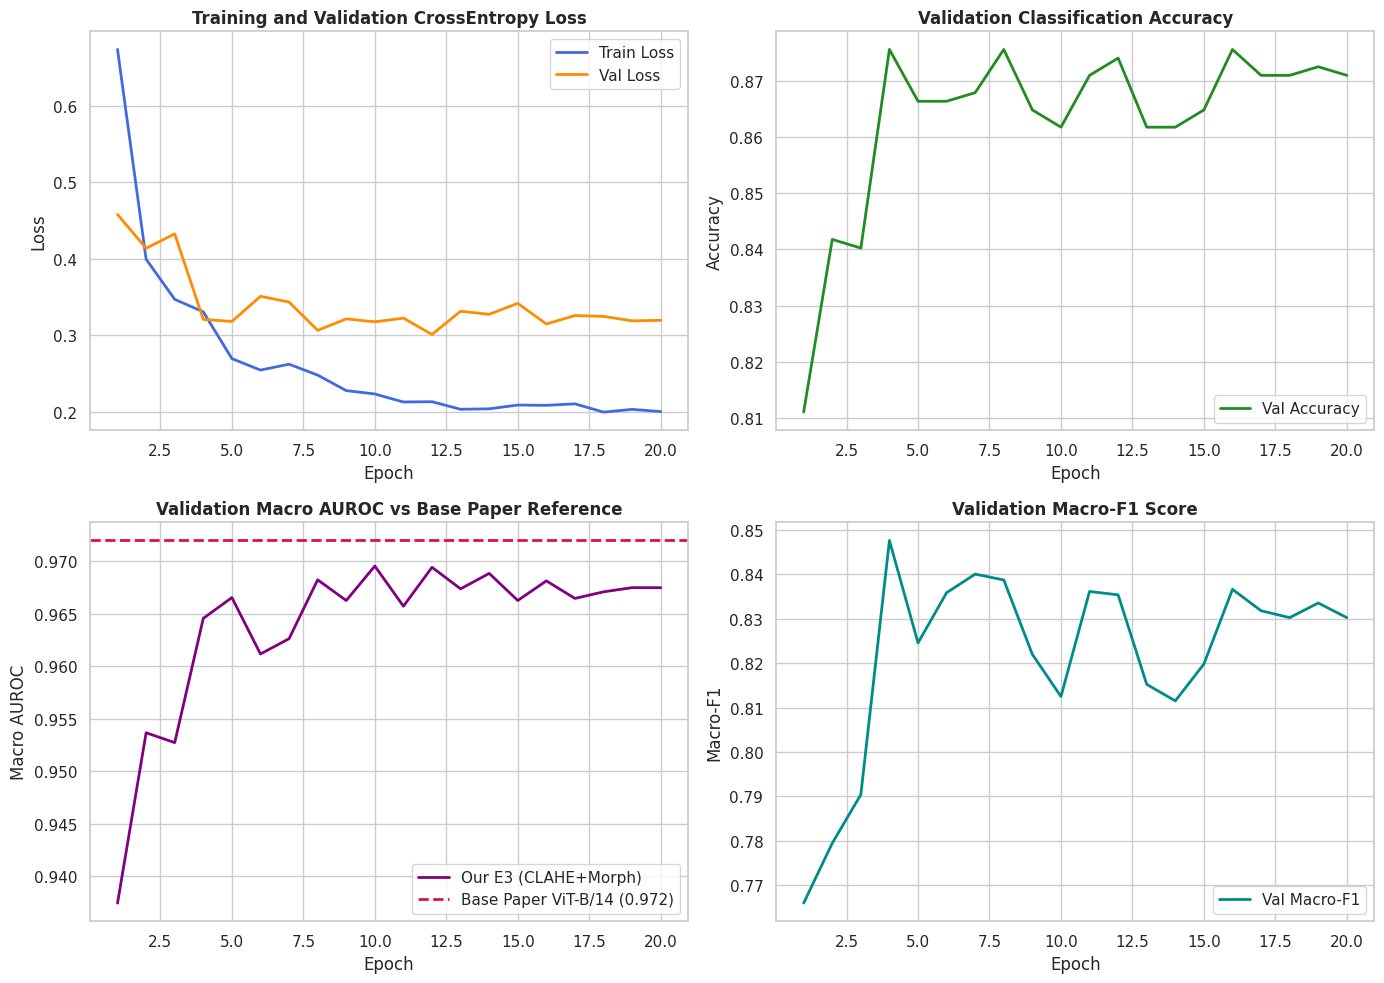

Classification Report (Validation Split):
              precision    recall  f1-score   support

  Meningioma     0.7895    0.5208    0.6276       144
      Glioma     0.9213    0.9480    0.9345       346
   Pituitary     0.7900    0.9814    0.8753       161

    accuracy                         0.8618       651
   macro avg     0.8336    0.8167    0.8125       651
weighted avg     0.8597    0.8618    0.8520       651



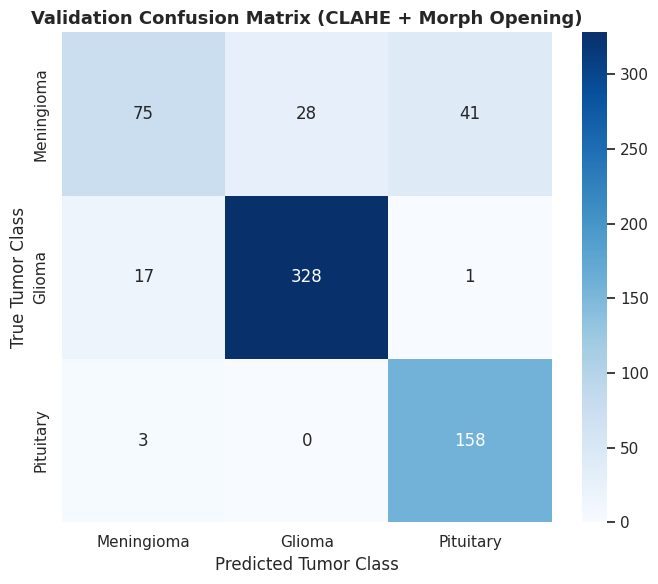

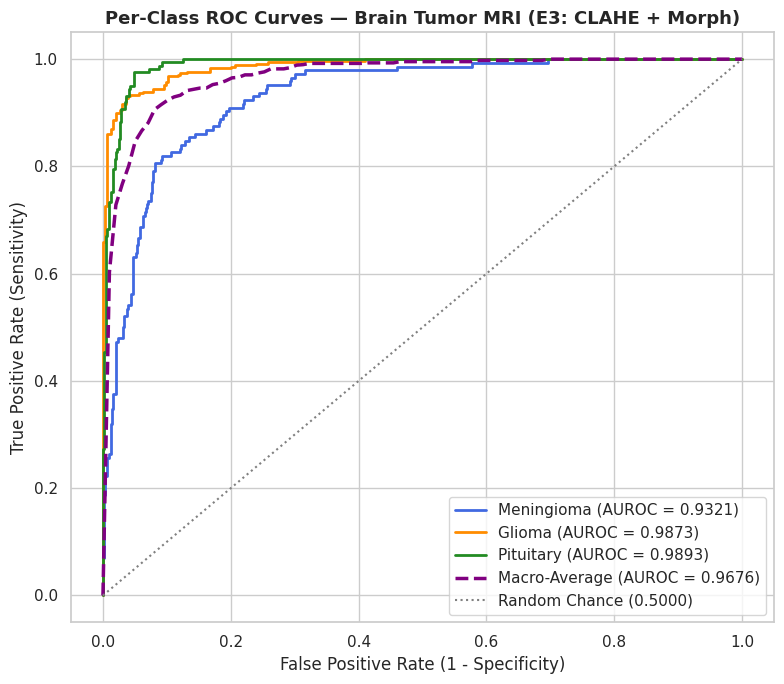

Saved results to outputs/exp3_pre_clahe_brain_tumor/results.json and appended run to experiment_log.csv


In [11]:
import csv
from datetime import datetime
from sklearn.metrics import auc, classification_report, confusion_matrix, roc_curve

# 1. Re-evaluate best checkpoint on Validation and Test sets
model.eval()
val_probs_list, val_labels_list = [], []
with torch.no_grad():
    for batch in val_loader:
        logits = model(batch["pixel_values"].to(device))
        val_probs_list.append(F.softmax(logits, dim=-1).cpu().numpy())
        val_labels_list.append(batch["label"].numpy())

all_val_probs = np.concatenate(val_probs_list, axis=0)
all_val_labels = np.concatenate(val_labels_list, axis=0)
all_val_preds = np.argmax(all_val_probs, axis=1)
val_metrics = compute_multiclass_metrics(all_val_labels, all_val_probs)

# 2. Plot 2x2 Training Curves
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
epochs_range = range(1, num_epochs + 1)

axes[0, 0].plot(epochs_range, history["train_loss"], label="Train Loss", color="royalblue", lw=2)
axes[0, 0].plot(epochs_range, history["val_loss"], label="Val Loss", color="darkorange", lw=2)
axes[0, 0].set_title("Training and Validation CrossEntropy Loss", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()

axes[0, 1].plot(epochs_range, history["val_accuracy"], label="Val Accuracy", color="forestgreen", lw=2)
axes[0, 1].set_title("Validation Classification Accuracy", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Accuracy")
axes[0, 1].legend(loc="lower right")

target_auroc = BASE_PAPER_RESULTS["DINOv2 ViT-B/14 (Target)"]["auroc"]
axes[1, 0].plot(epochs_range, history["val_macro_auroc"], label="Our E3 (CLAHE+Morph)", color="purple", lw=2)
axes[1, 0].axhline(y=target_auroc, color="crimson", linestyle="--", lw=2, label=f"Base Paper ViT-B/14 ({target_auroc:.3f})")
axes[1, 0].set_title("Validation Macro AUROC vs Base Paper Reference", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Macro AUROC")
axes[1, 0].legend(loc="lower right")

axes[1, 1].plot(epochs_range, history["val_macro_f1"], label="Val Macro-F1", color="darkcyan", lw=2)
axes[1, 1].set_title("Validation Macro-F1 Score", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Macro-F1")
axes[1, 1].legend(loc="lower right")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "exp3_pre_clahe_curves.png", dpi=300)
plt.show()

# 3. Confusion Matrix & Classification Report
cm = confusion_matrix(all_val_labels, all_val_preds)
print("Classification Report (Validation Split):")
print(classification_report(all_val_labels, all_val_preds, target_names=CLASS_LIST, digits=4))

fig_cm, ax_cm = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_LIST, yticklabels=CLASS_LIST, ax=ax_cm)
ax_cm.set_title("Validation Confusion Matrix (CLAHE + Morph Opening)", fontsize=13, fontweight="bold")
ax_cm.set_xlabel("Predicted Tumor Class")
ax_cm.set_ylabel("True Tumor Class")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "exp3_pre_clahe_confusion_matrix.png", dpi=300)
plt.show()

# 4. Per-Class & Macro ROC Curves
fig_roc, ax_roc = plt.subplots(figsize=(8, 7))
colors = ["royalblue", "darkorange", "forestgreen"]
macro_fpr = np.linspace(0.0, 1.0, 100)
tprs: list[np.ndarray] = []

for c_idx, c_name in CLASS_NAMES.items():
    binary_targets = (all_val_labels == c_idx).astype(int)
    fpr, tpr, _ = roc_curve(binary_targets, all_val_probs[:, c_idx])
    class_auc = auc(fpr, tpr)
    ax_roc.plot(fpr, tpr, color=colors[c_idx], lw=2, label=f"{c_name} (AUROC = {class_auc:.4f})")
    interp_tpr = np.interp(macro_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs.append(interp_tpr)

macro_tpr = np.mean(tprs, axis=0)
macro_tpr[-1] = 1.0
macro_auc = auc(macro_fpr, macro_tpr)
ax_roc.plot(macro_fpr, macro_tpr, color="purple", linestyle="--", lw=2.5, label=f"Macro-Average (AUROC = {macro_auc:.4f})")
ax_roc.plot([0, 1], [0, 1], color="gray", linestyle=":", lw=1.5, label="Random Chance (0.5000)")
ax_roc.set_xlabel("False Positive Rate (1 - Specificity)")
ax_roc.set_ylabel("True Positive Rate (Sensitivity)")
ax_roc.set_title("Per-Class ROC Curves — Brain Tumor MRI (E3: CLAHE + Morph)", fontsize=13, fontweight="bold")
ax_roc.legend(loc="lower right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "exp3_pre_clahe_roc_curves.png", dpi=300)
plt.show()

# 5. Self-Contained JSON & CSV Logging (No src.utils dependency)
results_summary = {
    "experiment": "exp3_pre_clahe_brain_tumor",
    "dataset": "BrainTumorMRI",
    "method": "LinearProbing_CLAHE_MorphOpen",
    "best_val_auroc": float(best_val_auroc),
    "best_val_accuracy": float(best_val_acc),
    "per_class_auroc": val_metrics["per_class_auroc"],
    "training_time_s": float(training_time_s),
    "history": history,
    "hparams": HPARAMS,
}

json_path = OUTPUT_DIR / "results.json"
with open(json_path, "w", encoding="utf-8") as f:
    json.dump(results_summary, f, indent=2)

csv_path = Path("experiment_log.csv")
csv_row = {
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "run_id": "exp3_pre_clahe_brain_tumor",
    "dataset": "BrainTumorMRI",
    "backbone": "DINOv2 ViT-B/14",
    "method": "LinearProbing_CLAHE_MorphOpen",
    "trainable_params": trainable_params,
    "total_params": total_params,
    "param_pct": round(param_pct, 4),
    "training_time_s": round(training_time_s, 2),
    "val_auroc": round(best_val_auroc, 4),
    "val_accuracy": round(best_val_acc, 4),
    "val_macro_f1": round(val_metrics["macro_f1"], 4),
    "seed": HPARAMS["seed"],
    "notes": "Foreground Clip [5,95] + CLAHE(clip=1.5, 8x8) + MorphOpen(3x3) blended(0.5)",
}
write_header = not csv_path.exists()
with open(csv_path, "a", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(csv_row.keys()))
    if write_header:
        writer.writeheader()
    writer.writerow(csv_row)

print(f"Saved results to {json_path} and appended run to {csv_path}")